# IFN680 — Project 7: Improving DDPM
## Training notebook — `DDPM_CosineSchedule.ipynb`

**Hypothesis under test:** *A cosine noise schedule allows a denoising diffusion probabilistic model (DDPM) to generate high-quality samples using fewer reverse-process steps than a linear schedule.*

This notebook trains **two conditional DDPMs** on the `mnist_custom.pt` dataset that are identical in every respect (U-Net architecture, hyperparameters, optimiser, number of epochs, random seed) **except for the beta (variance) schedule**:

1. **Model A — Linear schedule**, using `linear_beta_schedule` (as defined in the 9.3 Tutorial).
2. **Model B — Cosine schedule**, using a custom `cosine_beta_schedule` implementation (Nichol & Dhariwal, 2021).

Keeping everything else fixed isolates the noise schedule as the sole experimental variable, so any difference observed later (in `main_report.ipynb`) can be attributed to the schedule itself.

All shared code (dataset wrapper, schedules, the conditional U-Net, the training loop, and the DDPM sampler) lives in **`ddpm_utils.py`** — imported here and again in `main_report.ipynb`, so both notebooks always use identical implementations and the two runs stay strictly comparable.

This notebook follows the structure of the **9.3 Tutorial** as closely as possible: dataset setup → forward diffusion process → conditional U-Net → training loop → backward (sampling) process → generated results.

**Outputs of this notebook** (saved under `checkpoints/`):
- `linear_ddpm.pt`, `cosine_ddpm.pt` — trained model weights + schedule config.
- `linear_train_log.pkl`, `cosine_train_log.pkl` — per-epoch loss history + total training time.
- `classifier.pt` — small auxiliary CNN (trained on the real dataset) used only in `main_report.ipynb` to quantitatively score generated digits.

> **Note:** This notebook is provided un-run. Run it top-to-bottom on the IFN680 GPU environment; it will populate `checkpoints/` with everything `main_report.ipynb` needs.

In [1]:
import os
import json
import pickle
import time

import torch
import numpy as np
import matplotlib.pyplot as plt

import ddpm_utils as U

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
if device.type == "cuda":
    torch.cuda.manual_seed(0)

Using device: cuda


## 1. Dataset setup

`mnist_custom.pt` is **not** the standard torchvision MNIST: it stores 20x20 grayscale images (instead of 28x28) as a dict with keys `train_images`, `train_labels`, `test_images`, `test_labels`. Pixel values are float32 in `[0, 1]`; `MNISTCustomDataset` (in `ddpm_utils.py`) rescales them to `[-1, 1]` for the diffusion model, exactly as the 9.3 Tutorial does for standard MNIST.

In [2]:
# --- Paths & config -------------------------------------------------------
DATA_PATH = "mnist_custom.pt"          # place mnist_custom.pt next to this notebook
CHECKPOINT_DIR = "checkpoints"
FIGURE_DIR = "figures"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# --- Load data --------------------------------------------------------------
train_dataset, test_dataset = U.load_mnist_custom(DATA_PATH)
print(f"Train samples: {len(train_dataset)} | Test samples: {len(test_dataset)}")

image_size = train_dataset.images.shape[-1]
channels = train_dataset.images.shape[1]
print(f"Image size: {image_size}x{image_size}, channels: {channels}")

bs_train = 128
bs_test = 128
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=bs_train, shuffle=True,
                                                num_workers=0, pin_memory=False)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=bs_test, shuffle=False,
                                               num_workers=0, pin_memory=False)

Train samples: 60000 | Test samples: 10000
Image size: 20x20, channels: 1


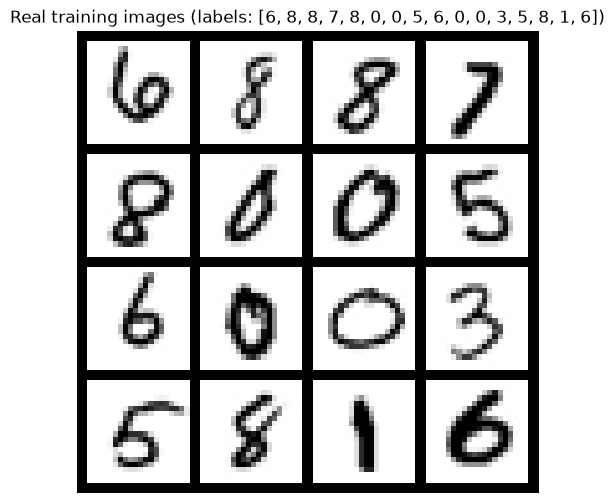

In [3]:
# Sanity-check: visualise a batch of real training images
from torchvision import utils as vutils

imgs, labels = next(iter(train_dataloader))
imgs = imgs[:16]
plt.figure(figsize=(6, 6))
grid = vutils.make_grid((imgs + 1) / 2, nrow=4)
plt.imshow(grid.permute(1, 2, 0).cpu())
plt.axis("off")
plt.title(f"Real training images (labels: {labels[:16].tolist()})")
plt.show()

## 2. Forward diffusion process — linear vs. cosine schedule

The forward process gradually destroys signal according to $\bar\alpha_t = \prod_{i=1}^t (1-\beta_i)$. The **linear** schedule increases $\beta_t$ steadily, which causes $\bar\alpha_t$ to collapse towards 0 quite early (relative to $T$) — most of the trajectory is spent in a near-pure-noise regime. The **cosine** schedule (Nichol & Dhariwal, 2021) instead keeps $\bar\alpha_t$ close to 1 for longer near $t=0$ and near $T$, and removes signal more gradually in between. This is the mechanism the project's hypothesis is built on: if the cosine schedule keeps more usable signal for more of the trajectory, a coarser (fewer-step) reverse process should still land close to the data manifold.

In [4]:
timesteps = 1000  # T used to TRAIN both models. Reduce if GPU time is limited.

schedule_linear = U.NoiseSchedule.linear(timesteps, device)   # beta_start=1e-4, beta_end=0.02 (9.3 Tutorial defaults)
schedule_cosine = U.NoiseSchedule.cosine(timesteps, device)   # s=0.008 (Nichol & Dhariwal default)

print("Linear  betas[0], betas[-1]:", schedule_linear.betas[0].item(), schedule_linear.betas[-1].item())
print("Cosine  betas[0], betas[-1]:", schedule_cosine.betas[0].item(), schedule_cosine.betas[-1].item())

Linear  betas[0], betas[-1]: 9.999999747378752e-05 0.019999999552965164
Cosine  betas[0], betas[-1]: 9.999999747378752e-05 0.9990000128746033


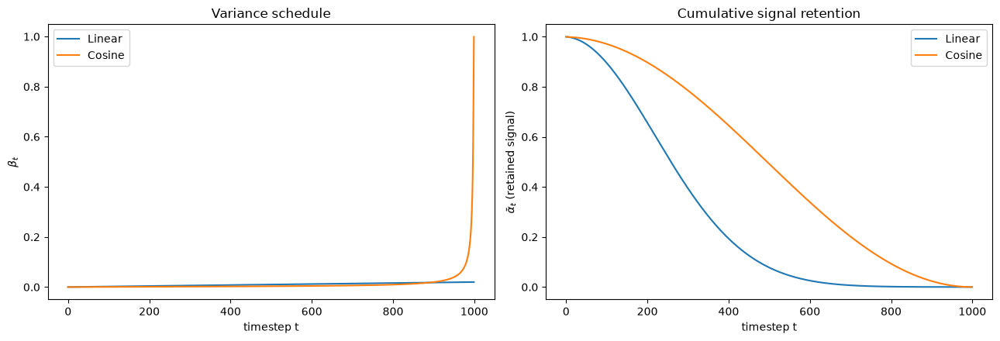

In [5]:
# Compare the two schedules directly
t_axis = np.arange(timesteps)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(t_axis, schedule_linear.betas.cpu(), label="Linear")
axes[0].plot(t_axis, schedule_cosine.betas.cpu(), label="Cosine")
axes[0].set_xlabel("timestep t")
axes[0].set_ylabel(r"$\beta_t$")
axes[0].set_title("Variance schedule")
axes[0].legend()

axes[1].plot(t_axis, schedule_linear.alpha_bars.cpu(), label="Linear")
axes[1].plot(t_axis, schedule_cosine.alpha_bars.cpu(), label="Cosine")
axes[1].set_xlabel("timestep t")
axes[1].set_ylabel(r"$\bar\alpha_t$ (retained signal)")
axes[1].set_title("Cumulative signal retention")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "schedule_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

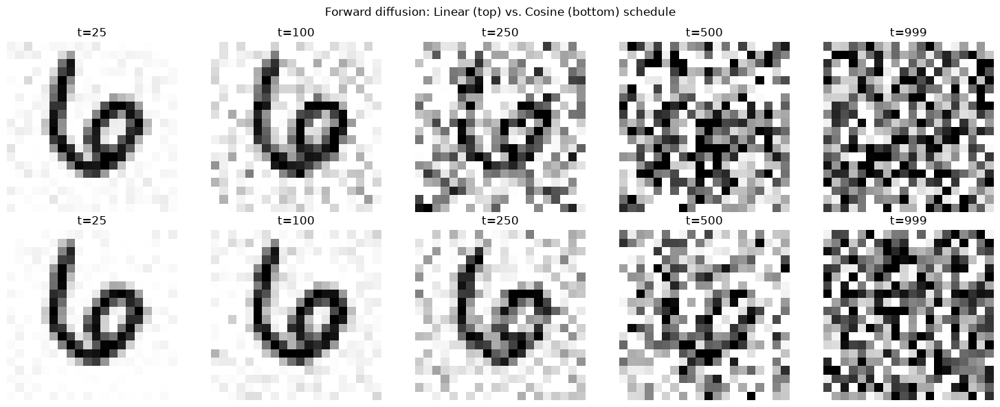

In [6]:
# Visualise forward noising of a real image under both schedules at matched timesteps
sample_img = imgs[:1].to(device)
# fractions of T rather than hardcoded steps, so this still works if `timesteps` is lowered
timesteps_investigated = sorted(set(int(timesteps * f) for f in [0.025, 0.1, 0.25, 0.5, 0.999]))

fig, axes = plt.subplots(2, len(timesteps_investigated), figsize=(3 * len(timesteps_investigated), 6))
for schedule, row, name in [(schedule_linear, 0, "Linear"), (schedule_cosine, 1, "Cosine")]:
    for col, t_val in enumerate(timesteps_investigated):
        t = torch.tensor([t_val], device=device)
        noised = U.q_sample(sample_img, t, schedule).clamp(-1, 1)
        axes[row, col].imshow(((noised[0, 0] + 1) / 2).cpu(), cmap="gray")
        axes[row, col].axis("off")
        axes[row, col].set_title(f"t={t_val}")
    axes[row, 0].set_ylabel(name, fontsize=12)

plt.suptitle("Forward diffusion: Linear (top) vs. Cosine (bottom) schedule")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "forward_noising_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Conditional U-Net architecture

Both models share the **exact same** `UNetCond` backbone (defined once in `ddpm_utils.py`, following the 9.3 Tutorial's `UNet_cond`): a 2-level encoder/decoder with skip connections, additive timestep + class-label conditioning injected at every resolution via a learned embedding. Fixing the architecture (and every other hyperparameter) between the two runs means the schedule is the only thing that differs.

In [7]:
n_channels_unet = 32
n_classes = 10

model_test = U.UNetCond(channels=channels, ch=n_channels_unet, n_classes=n_classes, timesteps=timesteps).to(device)
n_params = sum(p.numel() for p in model_test.parameters())
print(f"UNetCond parameter count: {n_params:,}")
del model_test

UNetCond parameter count: 221,569


## 4. Train the Linear-Schedule model (Model A)

In [8]:
epochs = 150      # 9.3 Tutorial default for the 10-class conditional model; lower if GPU time is limited
lr = 2e-4

torch.manual_seed(0)
model_linear = U.UNetCond(channels=channels, ch=n_channels_unet, n_classes=n_classes, timesteps=timesteps).to(device)

loss_history_linear, training_time_linear = U.train_ddpm(
    model_linear, schedule_linear, train_dataloader, epochs=epochs, lr=lr, device=device, run_name="linear"
)
print(f"[Linear] training time: {training_time_linear:.2f}s | final epoch loss: {loss_history_linear[-1]:.5f}")

[linear] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s]

[linear] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s, loss=1.38]

[linear] epoch 1/150:   0%|          | 1/469 [00:00<02:52,  2.72batch/s, loss=1.38]

[linear] epoch 1/150:   0%|          | 1/469 [00:00<02:52,  2.72batch/s, loss=1.24]

[linear] epoch 1/150:   0%|          | 1/469 [00:00<02:52,  2.72batch/s, loss=1.22]

[linear] epoch 1/150:   0%|          | 1/469 [00:00<02:52,  2.72batch/s, loss=1.31]

... (77,449 outputs left out)

[linear] epoch 150/150: 100%|█████████▉| 468/469 [00:05<00:00, 83.45batch/s, loss=0.0353]

[linear] epoch 150/150: 100%|█████████▉| 468/469 [00:05<00:00, 83.45batch/s, loss=0.0271]

[linear] epoch 150/150: 100%|██████████| 469/469 [00:05<00:00, 81.09batch/s, loss=0.0271]

[Linear] training time: 745.50s | final epoch loss: 0.02826


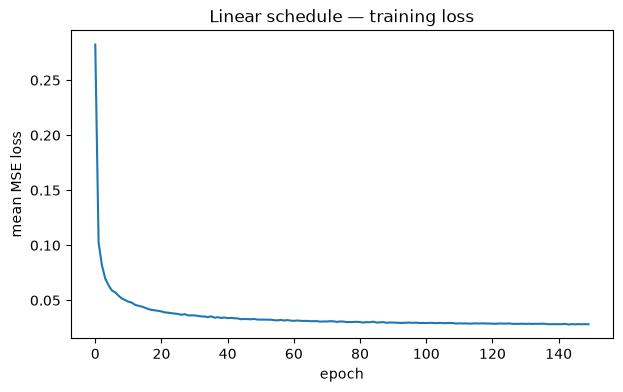

Saved linear_ddpm.pt and linear_train_log.pkl


In [9]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history_linear)
plt.xlabel("epoch")
plt.ylabel("mean MSE loss")
plt.title("Linear schedule — training loss")
plt.savefig(os.path.join(FIGURE_DIR, "loss_linear.png"), dpi=150, bbox_inches="tight")
plt.show()

U.save_ddpm_checkpoint(
    os.path.join(CHECKPOINT_DIR, "linear_ddpm.pt"), model_linear,
    schedule_name="linear", schedule_kwargs={"beta_start": 1e-4, "beta_end": 0.02},
    timesteps=timesteps, ch=n_channels_unet, n_classes=n_classes, image_size=image_size,
)
with open(os.path.join(CHECKPOINT_DIR, "linear_train_log.pkl"), "wb") as f:
    pickle.dump({"loss_history": loss_history_linear, "training_time": training_time_linear,
                 "epochs": epochs, "lr": lr}, f)
print("Saved linear_ddpm.pt and linear_train_log.pkl")

## 5. Train the Cosine-Schedule model (Model B)

Same architecture, same hyperparameters, same seed — only `schedule_cosine` differs from Section 4.

In [10]:
torch.manual_seed(0)
model_cosine = U.UNetCond(channels=channels, ch=n_channels_unet, n_classes=n_classes, timesteps=timesteps).to(device)

loss_history_cosine, training_time_cosine = U.train_ddpm(
    model_cosine, schedule_cosine, train_dataloader, epochs=epochs, lr=lr, device=device, run_name="cosine"
)
print(f"[Cosine] training time: {training_time_cosine:.2f}s | final epoch loss: {loss_history_cosine[-1]:.5f}")

[cosine] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s]

[cosine] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s, loss=1.38]

[cosine] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s, loss=1.24]

[cosine] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s, loss=1.22]

[cosine] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s, loss=1.31]

[cosine] epoch 1/150:   0%|          | 0/469 [00:00<?, ?batch/s, loss=1.2] 

... (77,523 outputs left out)

[cosine] epoch 150/150:  98%|█████████▊| 460/469 [00:04<00:00, 91.36batch/s, loss=0.0553]

[cosine] epoch 150/150:  98%|█████████▊| 460/469 [00:04<00:00, 91.36batch/s, loss=0.0479]

[cosine] epoch 150/150: 100%|██████████| 469/469 [00:04<00:00, 94.36batch/s, loss=0.0479]

[Cosine] training time: 753.98s | final epoch loss: 0.04900


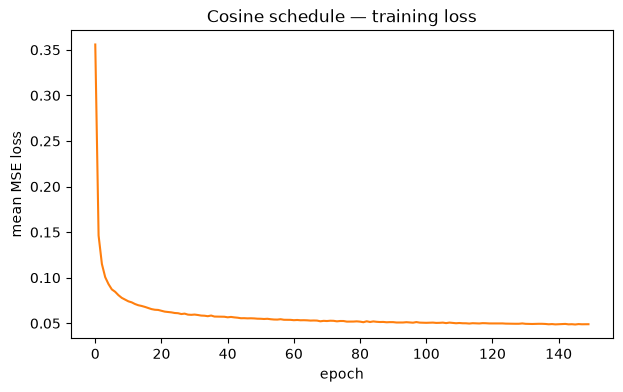

Saved cosine_ddpm.pt and cosine_train_log.pkl


In [11]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history_cosine, color="tab:orange")
plt.xlabel("epoch")
plt.ylabel("mean MSE loss")
plt.title("Cosine schedule — training loss")
plt.savefig(os.path.join(FIGURE_DIR, "loss_cosine.png"), dpi=150, bbox_inches="tight")
plt.show()

U.save_ddpm_checkpoint(
    os.path.join(CHECKPOINT_DIR, "cosine_ddpm.pt"), model_cosine,
    schedule_name="cosine", schedule_kwargs={"s": 0.008},
    timesteps=timesteps, ch=n_channels_unet, n_classes=n_classes, image_size=image_size,
)
with open(os.path.join(CHECKPOINT_DIR, "cosine_train_log.pkl"), "wb") as f:
    pickle.dump({"loss_history": loss_history_cosine, "training_time": training_time_cosine,
                 "epochs": epochs, "lr": lr}, f)
print("Saved cosine_ddpm.pt and cosine_train_log.pkl")

## 6. Auxiliary digit classifier (for quantitative evaluation in `main_report.ipynb`)

This small CNN is **not** part of either diffusion model. It is trained once on the real `mnist_custom.pt` training images and is used purely as an evaluation tool in `main_report.ipynb`: it scores whether a generated image is recognisable as the digit it was conditioned on, giving a quantitative "class-consistency" measure to complement the visual grids (useful when comparing quality across different numbers of sampling steps).

In [12]:
classifier = U.train_classifier(train_dataset, device, epochs=5, batch_size=256, lr=1e-3, image_size=image_size)

# Sanity check on the real held-out test set
test_imgs, test_labels = next(iter(test_dataloader))
test_acc = U.classifier_accuracy(classifier, test_imgs, test_labels, device)
print(f"Auxiliary classifier accuracy on a real test batch: {test_acc * 100:.2f}%")

torch.save({"state_dict": classifier.state_dict(), "image_size": image_size, "n_classes": n_classes},
           os.path.join(CHECKPOINT_DIR, "classifier.pt"))
print("Saved classifier.pt")

[classifier] epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s]

[classifier] epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s, loss=2.3]

[classifier] epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s, loss=2.3]

[classifier] epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s, loss=2.29]

[classifier] epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s, loss=2.28]

[classifier] epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s, loss=2.27]

... (1,227 outputs left out)

[classifier] epoch 5/5:  94%|█████████▍| 222/235 [00:01<00:00, 202.52it/s, loss=0.0478]

[classifier] epoch 5/5:  94%|█████████▍| 222/235 [00:01<00:00, 202.52it/s, loss=0.0449]

[classifier] epoch 5/5: 100%|██████████| 235/235 [00:01<00:00, 207.83it/s, loss=0.0449]

Auxiliary classifier accuracy on a real test batch: 99.22%
Saved classifier.pt


## 7. Quick sanity-check generation

A small conditional sample from each freshly-trained model, just to confirm training worked before moving to `main_report.ipynb` for the full 12x10 comparison and the fewer-steps experiments.

Sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

Sampling (1000 steps):   2%|▏         | 21/1000 [00:00<00:04, 209.31it/s]

Sampling (1000 steps):   5%|▌         | 51/1000 [00:00<00:03, 258.85it/s]

Sampling (1000 steps):   8%|▊         | 77/1000 [00:00<00:03, 255.67it/s]

Sampling (1000 steps):  11%|█▏        | 114/1000 [00:00<00:02, 297.23it/s]

Sampling (1000 steps):  15%|█▍        | 147/1000 [00:00<00:02, 306.24it/s]

... (21 outputs left out)

Sampling (1000 steps):  91%|█████████ | 909/1000 [00:02<00:00, 328.55it/s]

Sampling (1000 steps):  94%|█████████▍| 944/1000 [00:02<00:00, 332.76it/s]

Sampling (1000 steps):  98%|█████████▊| 979/1000 [00:02<00:00, 337.06it/s]

Sampling (1000 steps): 100%|██████████| 1000/1000 [00:03<00:00, 326.05it/s]

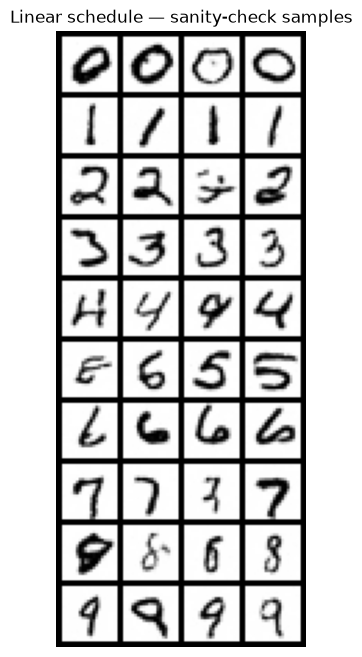

Sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

Sampling (1000 steps):   3%|▎         | 34/1000 [00:00<00:02, 334.02it/s]

Sampling (1000 steps):   7%|▋         | 68/1000 [00:00<00:02, 314.46it/s]

Sampling (1000 steps):  10%|█         | 102/1000 [00:00<00:02, 324.15it/s]

Sampling (1000 steps):  14%|█▎        | 135/1000 [00:00<00:02, 316.30it/s]

Sampling (1000 steps):  17%|█▋        | 171/1000 [00:00<00:02, 329.04it/s]

... (21 outputs left out)

Sampling (1000 steps):  93%|█████████▎| 929/1000 [00:02<00:00, 256.49it/s]

Sampling (1000 steps):  97%|█████████▋| 966/1000 [00:03<00:00, 284.02it/s]

Sampling (1000 steps): 100%|█████████▉| 996/1000 [00:03<00:00, 241.20it/s]

Sampling (1000 steps): 100%|██████████| 1000/1000 [00:03<00:00, 312.44it/s]

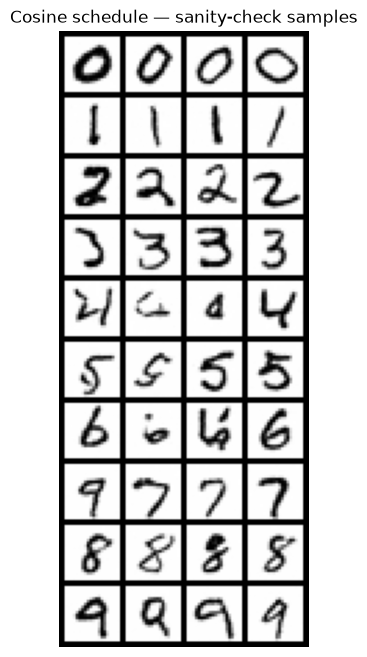

In [13]:
sanity_labels = U.make_class_conditioned_labels(n_classes=10, samples_per_class=4, device=device)

samples_linear = U.sample_ddpm(model_linear, schedule_linear, sanity_labels, image_size=image_size,
                                channels=channels, device=device, seed=1337)
U.plot_grid(samples_linear, nrow=4, title="Linear schedule — sanity-check samples")

samples_cosine = U.sample_ddpm(model_cosine, schedule_cosine, sanity_labels, image_size=image_size,
                                channels=channels, device=device, seed=1337)
U.plot_grid(samples_cosine, nrow=4, title="Cosine schedule — sanity-check samples")

---
### Summary

`checkpoints/` now contains everything `main_report.ipynb` needs to reproduce the full comparison and generate the report's figures and numbers, without retraining:

- `linear_ddpm.pt`, `cosine_ddpm.pt`
- `linear_train_log.pkl`, `cosine_train_log.pkl`
- `classifier.pt`

Proceed to **`main_report.ipynb`**.